# HW4.5 - GPU Assignment II
## Training Throughput and Memory Engineering

**Student:** Nikhil Kanaparthi  
**SID4:** 6441  


In [1]:
# 0. Install dependencies
%pip -q install transformers datasets accelerate scikit-learn seaborn bitsandbytes sentencepiece

In [2]:

# 1. Configuration, reproducibility, and GPU provenance
import os, sys, json, time, math, gc, shutil, subprocess, random, warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support

# I preserve my HW4.a personal parameters.
SID4 = 6441
SEED = 6441
SLICE = 441
MAX_ROWS = 5000

# I keep these settings in one place so I can match my HW4.a notebook exactly if needed.
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 128
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
EPOCHS = 2
SCALING_EPOCHS = 1
TECHNIQUE_EPOCHS = 2
BASELINE_BATCH_SIZE = 16
BATCH_CANDIDATES = [4, 8, 16, 32, 64, 128]
NUM_WORKERS = 2
PIN_MEMORY = True

# The previous HW4.a memory/time values were not available in the recovered files.
# I leave these as None instead of inventing them. The notebook records a fresh comparable baseline.
HW4_A_BASELINE_PEAK_MEMORY_GB = None
HW4_A_BASELINE_WALL_SECONDS = None

RUN_START_UTC = datetime.now(timezone.utc).isoformat()
OUTPUT_DIR = Path("/content/HW4_5_outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = OUTPUT_DIR / "models"
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

def log_event(message):
    line = f"[{datetime.now(timezone.utc).isoformat()}] {message}"
    print(line)
    with open(OUTPUT_DIR / "RUN_LOG.txt", "a", encoding="utf-8") as handle:
        handle.write(line + "\n")

def command_output(command):
    try:
        return subprocess.check_output(command, shell=True, text=True, stderr=subprocess.STDOUT)
    except Exception as exc:
        return "COMMAND FAILED: " + str(exc)

assert torch.cuda.is_available(), "I must enable Runtime > Change runtime type > GPU in Colab."
DEVICE = torch.device("cuda")
properties = torch.cuda.get_device_properties(0)
GPU_NAME = torch.cuda.get_device_name(0)
GPU_UUID = command_output("nvidia-smi --query-gpu=uuid --format=csv,noheader").strip().splitlines()[0]
DRIVER_VERSION = command_output("nvidia-smi --query-gpu=driver_version --format=csv,noheader").strip().splitlines()[0]
CUDA_VERSION = torch.version.cuda

(OUTPUT_DIR / "nvidia-smi-q.txt").write_text(command_output("nvidia-smi -q"), encoding="utf-8")
(OUTPUT_DIR / "nvidia-smi-L.txt").write_text(command_output("nvidia-smi -L"), encoding="utf-8")
provenance = {
    "gpu_name": GPU_NAME,
    "gpu_uuid": GPU_UUID,
    "driver_version": DRIVER_VERSION,
    "cuda_version": CUDA_VERSION,
    "vram_gib": round(properties.total_memory / 2**30, 3),
    "compute_capability": f"{properties.major}.{properties.minor}",
    "run_start_utc": RUN_START_UTC
}
(OUTPUT_DIR / "gpu_provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

log_event(f"I started HW4.5 on {GPU_NAME}; UUID={GPU_UUID}; CUDA={CUDA_VERSION}")
print(json.dumps(provenance, indent=2))


[2026-11-03T02:58:10.683681+00:00] I started HW4.5 on Tesla T4; UUID=GPU-ef1369de-78dd-c684-4e6a-c14668cb81c9; CUDA=13.0
{
  "gpu_name": "Tesla T4",
  "gpu_uuid": "GPU-ef1369de-78dd-c684-4e6a-c14668cb81c9",
  "driver_version": "580.82.07",
  "cuda_version": "13.0",
  "vram_gib": 14.563,
  "compute_capability": "7.5",
  "run_start_utc": "2026-11-03T02:58:10.219825+00:00"
}


In [3]:

# 2. Load the exact HW4.a dataset and preserve the required row range
from pathlib import Path
from google.colab import files

candidate_paths = [
    Path("/content/IMDB Dataset.csv.zip"),
    Path("/content/IMDB Dataset.csv"),
]

dataset_path = next((path for path in candidate_paths if path.exists()), None)
if dataset_path is None:
    # I download the same 50,000-row CSV format directly inside Colab.
    dataset_path = Path("/content/IMDB Dataset.csv")
    dataset_url = "https://raw.githubusercontent.com/SK7here/Movie-Review-Sentiment-Analysis/master/IMDB-Dataset.csv"
    print("I did not find the dataset locally, so I am downloading it inside Colab...")
    import urllib.request
    urllib.request.urlretrieve(dataset_url, dataset_path)
    print("I downloaded:", dataset_path)

if dataset_path.suffix.lower() == ".zip":
    imdb_df = pd.read_csv(dataset_path, compression="zip")
else:
    imdb_df = pd.read_csv(dataset_path)

assert {"review", "sentiment"}.issubset(imdb_df.columns), "The dataset must contain review and sentiment columns."
assert len(imdb_df) >= SLICE + 1, "The dataset does not contain the required starting row."
imdb_df = imdb_df[["review", "sentiment"]].dropna().reset_index(drop=True)
imdb_df["label"] = imdb_df["sentiment"].map({"negative": 0, "positive": 1})
assert imdb_df["label"].notna().all(), "Unexpected sentiment labels were found."

working_df = imdb_df.iloc[SLICE:SLICE + MAX_ROWS].copy().reset_index(drop=True)
actual_start = SLICE
actual_end = SLICE + len(working_df) - 1
assert len(working_df) == min(MAX_ROWS, len(imdb_df) - SLICE)

train_df, temporary_df = train_test_split(
    working_df, test_size=0.30, random_state=SEED, stratify=working_df["label"]
)
validation_df, test_df = train_test_split(
    temporary_df, test_size=0.50, random_state=SEED, stratify=temporary_df["label"]
)
train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

split_manifest = {
    "dataset": "IMDB Dataset.csv",
    "columns": ["review", "sentiment"],
    "slice_start_zero_based": actual_start,
    "slice_end_zero_based_inclusive": actual_end,
    "rows_used": len(working_df),
    "split_rule": "70% train, 15% validation, 15% test",
    "seed": SEED,
    "train_rows": len(train_df),
    "validation_rows": len(validation_df),
    "test_rows": len(test_df)
}
(OUTPUT_DIR / "split_manifest.json").write_text(json.dumps(split_manifest, indent=2), encoding="utf-8")
log_event(f"I used dataset rows {actual_start}-{actual_end} inclusive with seed {SEED}.")
print(split_manifest)
display(working_df.head(3))
display(working_df["sentiment"].value_counts().rename("count").to_frame())


I did not find the dataset locally, so I am downloading it inside Colab...
I downloaded: /content/IMDB Dataset.csv
[2026-11-03T02:58:13.402568+00:00] I used dataset rows 441-5440 inclusive with seed 6441.
{'dataset': 'IMDB Dataset.csv', 'columns': ['review', 'sentiment'], 'slice_start_zero_based': 441, 'slice_end_zero_based_inclusive': 5440, 'rows_used': 5000, 'split_rule': '70% train, 15% validation, 15% test', 'seed': 6441, 'train_rows': 3500, 'validation_rows': 750, 'test_rows': 750}


,review,sentiment,label
0,Although I was hoping that I'd like it a littl...,positive,1
1,Imagine this: a high school. Except it's board...,negative,0
2,I had been amazed by director Antal's Kontroll...,negative,0


,count
sentiment,
negative,2517
positive,2483


In [4]:

# 3. Tokenize the fixed train/validation/test split
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class ReviewDataset(torch.utils.data.Dataset):
    def __init__(self, frame):
        self.texts = frame["review"].tolist()
        self.labels = frame["label"].astype(int).tolist()
        self.encodings = tokenizer(
            self.texts,
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH
        )
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        item = {key: torch.tensor(value[index], dtype=torch.long) for key, value in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[index], dtype=torch.long)
        return item

train_dataset = ReviewDataset(train_df)
validation_dataset = ReviewDataset(validation_df)
test_dataset = ReviewDataset(test_df)
log_event("I created the fixed tensor datasets with the same split used for every experiment.")
print(len(train_dataset), len(validation_dataset), len(test_dataset))


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[2026-11-03T02:58:32.005607+00:00] I created the fixed tensor datasets with the same split used for every experiment.
3500 750 750


In [5]:

# 4. Training and evaluation utilities
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from copy import deepcopy

def build_model(checkpointing=False):
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2,
        id2label={0:"negative", 1:"positive"},
        label2id={"negative":0, "positive":1}
    )
    if checkpointing:
        model.gradient_checkpointing_enable()
        model.config.use_cache = False
    return model.to(DEVICE)

def make_optimizer(model, use_8bit=False):
    optimizer_status = "AdamW"
    if use_8bit:
        try:
            import bitsandbytes as bnb
            optimizer = bnb.optim.Adam8bit(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
            optimizer_status = "bitsandbytes Adam8bit"
            return optimizer, optimizer_status
        except Exception as exc:
            print("I could not activate the 8-bit optimizer; I will record the fallback:", exc)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    return optimizer, optimizer_status

def make_loader(dataset, batch_size, shuffle):
    return torch.utils.data.DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle,
        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
    )

def evaluate_model(model, dataset, batch_size):
    loader = make_loader(dataset, batch_size, shuffle=False)
    model.eval()
    total_loss = 0.0
    predictions, labels = [], []
    with torch.no_grad():
        for batch in loader:
            batch = {key:value.to(DEVICE, non_blocking=True) for key, value in batch.items()}
            outputs = model(**batch)
            total_loss += outputs.loss.item() * batch["labels"].size(0)
            predictions.extend(outputs.logits.argmax(dim=-1).detach().cpu().tolist())
            labels.extend(batch["labels"].detach().cpu().tolist())
    accuracy = float(np.mean(np.array(predictions) == np.array(labels)))
    return total_loss / len(dataset), accuracy, predictions, labels

def run_training(label, batch_size, epochs, use_amp=False, checkpointing=False,
                 gradient_accumulation=1, use_8bit=False, save_model=False):
    model = None
    try:
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()
        model = build_model(checkpointing=checkpointing)
        optimizer, optimizer_status = make_optimizer(model, use_8bit=use_8bit)
        train_loader = make_loader(train_dataset, batch_size, shuffle=True)
        total_updates = math.ceil(len(train_loader) / gradient_accumulation) * epochs
        scheduler = get_linear_schedule_with_warmup(
            optimizer, num_warmup_steps=max(1, int(0.1 * total_updates)),
            num_training_steps=max(1, total_updates)
        )
        scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
        history = []
        best_val_accuracy = -1.0
        best_epoch = 0
        start_all = time.perf_counter()
        optimizer.zero_grad(set_to_none=True)

        for epoch in range(1, epochs + 1):
            epoch_start = time.perf_counter()
            model.train()
            running_loss = 0.0
            seen = 0
            for step, batch in enumerate(train_loader, start=1):
                batch = {key:value.to(DEVICE, non_blocking=True) for key, value in batch.items()}
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                    outputs = model(**batch)
                    loss = outputs.loss / gradient_accumulation
                scaler.scale(loss).backward()
                running_loss += outputs.loss.item() * batch["labels"].size(0)
                seen += batch["labels"].size(0)
                if step % gradient_accumulation == 0 or step == len(train_loader):
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad(set_to_none=True)
                    scheduler.step()

            train_loss = running_loss / seen
            val_loss, val_accuracy, _, _ = evaluate_model(model, validation_dataset, batch_size)
            epoch_seconds = time.perf_counter() - epoch_start
            history.append({
                "epoch": epoch, "train_loss": train_loss, "validation_loss": val_loss,
                "validation_accuracy": val_accuracy, "epoch_seconds": epoch_seconds
            })
            if val_accuracy > best_val_accuracy:
                best_val_accuracy = val_accuracy
                best_epoch = epoch
            print(f"{label}: epoch {epoch}/{epochs} | train loss {train_loss:.4f} | validation loss {val_loss:.4f} | validation accuracy {val_accuracy:.4f} | {epoch_seconds:.1f}s")

        total_seconds = time.perf_counter() - start_all
        test_loss, test_accuracy, test_predictions, test_labels = evaluate_model(model, test_dataset, batch_size)
        peak_memory_gb = torch.cuda.max_memory_reserved() / 2**30
        result = {
            "label": label, "status": "success", "batch_size": batch_size,
            "physical_batch_size": batch_size, "effective_batch_size": batch_size * gradient_accumulation,
            "gradient_accumulation": gradient_accumulation, "use_amp": use_amp,
            "checkpointing": checkpointing, "use_8bit": use_8bit,
            "optimizer": optimizer_status, "epochs": epochs, "seconds": total_seconds,
            "seconds_per_epoch": total_seconds / epochs, "samples_per_second": len(train_dataset) * epochs / total_seconds,
            "peak_memory_gb": peak_memory_gb, "validation_accuracy": best_val_accuracy,
            "test_accuracy": test_accuracy, "best_epoch": best_epoch,
            "history": history, "test_predictions": test_predictions, "test_labels": test_labels
        }
        if save_model:
            model_dir = MODEL_DIR / label.replace(" ", "_").replace("/", "_")
            model_dir.mkdir(exist_ok=True, parents=True)
            model.save_pretrained(model_dir)
            tokenizer.save_pretrained(model_dir)
            result["model_dir"] = str(model_dir)
        return result
    except RuntimeError as exc:
        if "out of memory" not in str(exc).lower():
            raise
        print(f"{label}: CUDA out of memory at physical batch size {batch_size}.")
        return {
            "label": label, "status": "OOM", "batch_size": batch_size,
            "physical_batch_size": batch_size, "effective_batch_size": batch_size * gradient_accumulation,
            "gradient_accumulation": gradient_accumulation, "use_amp": use_amp,
            "checkpointing": checkpointing, "use_8bit": use_8bit,
            "peak_memory_gb": np.nan, "samples_per_second": np.nan,
            "test_accuracy": np.nan, "validation_accuracy": np.nan
        }
    finally:
        del model
        gc.collect()
        torch.cuda.empty_cache()


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_909/129

baseline: epoch 1/2 | train loss 0.4570 | validation loss 0.3247 | validation accuracy 0.8520 | 89.9s
baseline: epoch 2/2 | train loss 0.2143 | validation loss 0.3119 | validation accuracy 0.8667 | 98.5s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

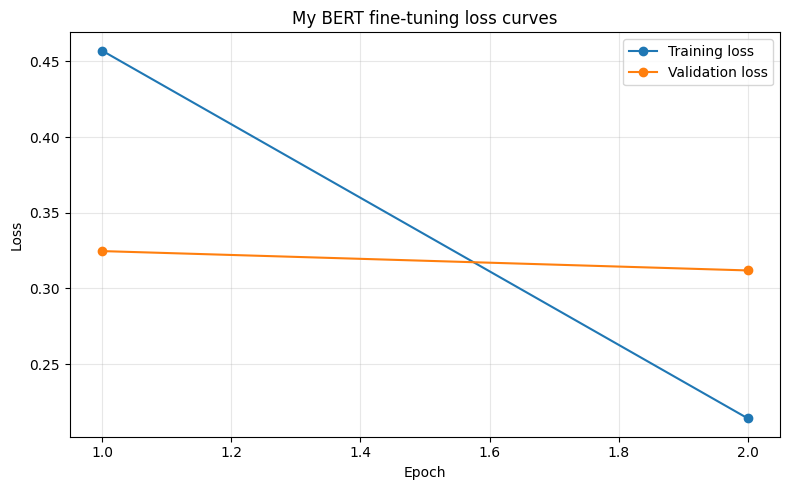

[2026-11-03T03:02:23.894355+00:00] I completed the HW4.a-equivalent baseline and saved its wall-clock and peak-memory measurements.


In [6]:

# 5. HW4.a-equivalent baseline and training curves
baseline_result = run_training(
    "baseline", BASELINE_BATCH_SIZE, EPOCHS,
    use_amp=False, checkpointing=False, gradient_accumulation=1,
    use_8bit=False, save_model=True
)
(OUTPUT_DIR / "baseline_result.json").write_text(
    json.dumps({key:value for key,value in baseline_result.items() if key not in ["history","test_predictions","test_labels"]}, indent=2, default=str),
    encoding="utf-8"
)
baseline_history = pd.DataFrame(baseline_result.get("history", []))
baseline_history.to_csv(OUTPUT_DIR / "baseline_training_history.csv", index=False)
if not baseline_history.empty:
    plt.figure(figsize=(8,5))
    plt.plot(baseline_history["epoch"], baseline_history["train_loss"], "o-", label="Training loss")
    plt.plot(baseline_history["epoch"], baseline_history["validation_loss"], "o-", label="Validation loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("My BERT fine-tuning loss curves")
    plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
    plt.savefig(FIGURE_DIR / "baseline_loss_curves.png", dpi=180); plt.show()
log_event("I completed the HW4.a-equivalent baseline and saved its wall-clock and peak-memory measurements.")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_909/129

scaling_batch_4: epoch 1/1 | train loss 0.4138 | validation loss 0.3094 | validation accuracy 0.8547 | 123.8s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


scaling_batch_8: epoch 1/1 | train loss 0.4160 | validation loss 0.3105 | validation accuracy 0.8653 | 108.0s


... (9 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


scaling_batch_128: epoch 1/1 | train loss 0.6853 | validation loss 0.6513 | validation accuracy 0.7480 | 89.5s


,label,status,batch_size,physical_batch_size,effective_batch_size,gradient_accumulation,use_amp,checkpointing,use_8bit,optimizer,epochs,seconds,seconds_per_epoch,samples_per_second,peak_memory_gb,validation_accuracy,test_accuracy,best_epoch
0,scaling_batch_4,success,4,4,4,1,False,False,False,AdamW,1,123.764904,123.764904,28.279422,2.251953,0.854667,0.854667,1
1,scaling_batch_8,success,8,8,8,1,False,False,False,AdamW,1,108.035989,108.035989,32.396612,2.275391,0.865333,0.860000,1
2,scaling_batch_16,success,16,16,16,1,False,False,False,AdamW,1,98.772277,98.772277,35.435044,2.816406,0.858667,0.842667,1
3,scaling_batch_32,success,32,32,32,1,False,False,False,AdamW,1,92.411050,92.411050,37.874259,3.957031,0.873333,0.834667,1
4,scaling_batch_64,success,64,64,64,1,False,False,False,AdamW,1,91.035646,91.035646,38.446479,6.263672,0.796000,0.757333,1
5,scaling_batch_128,success,128,128,128,1,False,False,False,AdamW,1,89.539676,89.539676,39.088817,11.082031,0.748000,0.722667,1


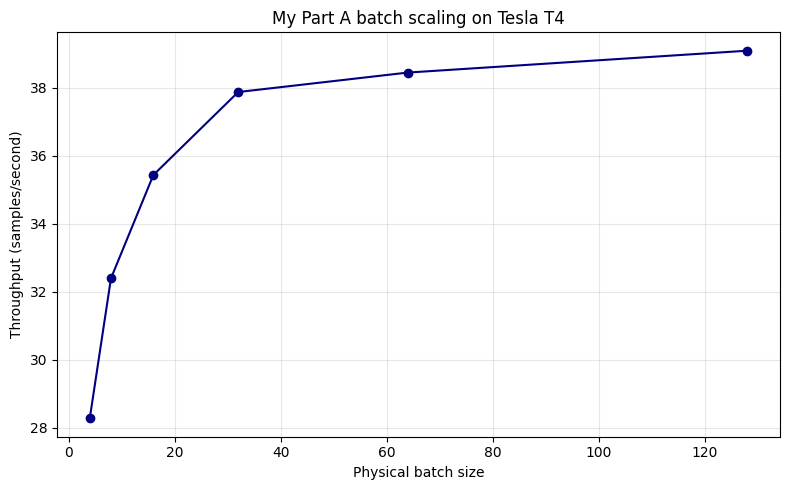

[2026-11-03T03:13:12.681936+00:00] My largest successful baseline batch was 128.


In [7]:

# 6. Part A - batch scaling to the memory wall
scaling_rows = []
for batch_size in BATCH_CANDIDATES:
    result = run_training(
        f"scaling_batch_{batch_size}", batch_size, SCALING_EPOCHS,
        use_amp=False, checkpointing=False, gradient_accumulation=1,
        use_8bit=False, save_model=False
    )
    scaling_rows.append({key:value for key,value in result.items() if key not in ["history","test_predictions","test_labels"]})
    if result["status"] == "OOM":
        break

scaling_df = pd.DataFrame(scaling_rows)
scaling_df.to_csv(OUTPUT_DIR / "part_a_batch_scaling.csv", index=False)
display(scaling_df)

successful_scaling = scaling_df[scaling_df["status"] == "success"]
largest_baseline_batch = int(successful_scaling["batch_size"].max()) if not successful_scaling.empty else None
plt.figure(figsize=(8,5))
plot_df = scaling_df[scaling_df["status"] == "success"]
plt.plot(plot_df["batch_size"], plot_df["samples_per_second"], "o-", color="navy")
plt.xlabel("Physical batch size"); plt.ylabel("Throughput (samples/second)")
plt.title(f"My Part A batch scaling on {GPU_NAME}")
plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(FIGURE_DIR / "part_a_throughput_vs_batch.png", dpi=180); plt.show()
log_event(f"My largest successful baseline batch was {largest_baseline_batch}.")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_909/129

scaling_batch_256: CUDA out of memory at physical batch size 256.
OOM reached at batch size 256.


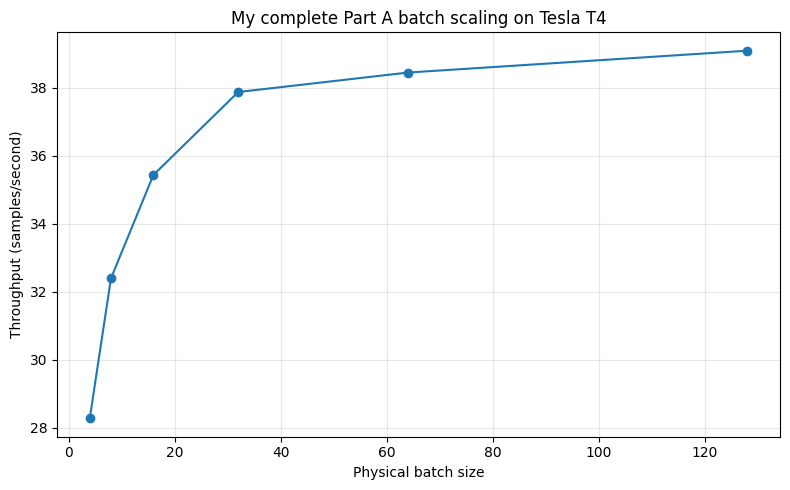

,label,status,batch_size,physical_batch_size,effective_batch_size,gradient_accumulation,use_amp,checkpointing,use_8bit,optimizer,epochs,seconds,seconds_per_epoch,samples_per_second,peak_memory_gb,validation_accuracy,test_accuracy,best_epoch
0,scaling_batch_4,success,4,4,4,1,False,False,False,AdamW,1.0,123.764904,123.764904,28.279422,2.251953,0.854667,0.854667,1.0
1,scaling_batch_8,success,8,8,8,1,False,False,False,AdamW,1.0,108.035989,108.035989,32.396612,2.275391,0.865333,0.860000,1.0
2,scaling_batch_16,success,16,16,16,1,False,False,False,AdamW,1.0,98.772277,98.772277,35.435044,2.816406,0.858667,0.842667,1.0
3,scaling_batch_32,success,32,32,32,1,False,False,False,AdamW,1.0,92.411050,92.411050,37.874259,3.957031,0.873333,0.834667,1.0
4,scaling_batch_64,success,64,64,64,1,False,False,False,AdamW,1.0,91.035646,91.035646,38.446479,6.263672,0.796000,0.757333,1.0
5,scaling_batch_128,success,128,128,128,1,False,False,False,AdamW,1.0,89.539676,89.539676,39.088817,11.082031,0.748000,0.722667,1.0
6,scaling_batch_256,OOM,256,256,256,1,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Largest successful batch: 128


In [9]:
# Continue Part A until the actual memory wall
extra_rows = []

for batch_size in [256, 512, 1024]:
    result = run_training(
        f"scaling_batch_{batch_size}",
        batch_size,
        SCALING_EPOCHS,
        use_amp=False,
        checkpointing=False,
        gradient_accumulation=1,
        use_8bit=False,
        save_model=False
    )

    row = {
        key: value
        for key, value in result.items()
        if key not in ["history", "test_predictions", "test_labels"]
    }
    extra_rows.append(row)

    if result["status"] == "OOM":
        print(f"OOM reached at batch size {batch_size}.")
        break

extra_df = pd.DataFrame(extra_rows)
scaling_df = pd.concat([scaling_df, extra_df], ignore_index=True)

scaling_df.to_csv(OUTPUT_DIR / "part_a_batch_scaling.csv", index=False)

successful_scaling = scaling_df[scaling_df["status"] == "success"]
largest_baseline_batch = int(successful_scaling["batch_size"].max())

plt.figure(figsize=(8, 5))
plot_df = scaling_df[scaling_df["status"] == "success"]
plt.plot(plot_df["batch_size"], plot_df["samples_per_second"], "o-")
plt.xlabel("Physical batch size")
plt.ylabel("Throughput (samples/second)")
plt.title(f"My complete Part A batch scaling on {GPU_NAME}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "part_a_throughput_vs_batch.png", dpi=180)
plt.show()

display(scaling_df)
print("Largest successful batch:", largest_baseline_batch)

In [10]:

# 7. Part B - measure memory techniques independently
def search_max_batch(name, options, **kwargs):
    records = []
    for batch_size in options:
        result = run_training(
            f"{name}_batch_{batch_size}", batch_size, TECHNIQUE_EPOCHS,
            save_model=False, **kwargs
        )
        row = {key:value for key,value in result.items() if key not in ["history","test_predictions","test_labels"]}
        records.append(row)
        if result["status"] == "OOM":
            break
    successful = [row for row in records if row["status"] == "success"]
    best = max(successful, key=lambda row: row["physical_batch_size"]) if successful else records[-1]
    return records, best

technique_records = []
technique_best = []

# I apply automatic mixed precision alone.
records, best = search_max_batch("mixed_precision", BATCH_CANDIDATES, use_amp=True, checkpointing=False, gradient_accumulation=1, use_8bit=False)
technique_records += records; technique_best.append(dict(best, technique="Automatic mixed precision"))

# I apply gradient checkpointing alone.
records, best = search_max_batch("checkpointing", BATCH_CANDIDATES, use_amp=False, checkpointing=True, gradient_accumulation=1, use_8bit=False)
technique_records += records; technique_best.append(dict(best, technique="Gradient checkpointing"))

# I apply gradient accumulation alone, using four accumulation steps.
records, best = search_max_batch("gradient_accumulation", BATCH_CANDIDATES, use_amp=False, checkpointing=False, gradient_accumulation=4, use_8bit=False)
technique_records += records
best = dict(best, technique="Gradient accumulation")
best["effective_batch_size"] = best["physical_batch_size"] * 4
technique_best.append(best)

# I apply an 8-bit optimizer alone.
records, best = search_max_batch("eight_bit_optimizer", BATCH_CANDIDATES, use_amp=False, checkpointing=False, gradient_accumulation=1, use_8bit=True)
technique_records += records; technique_best.append(dict(best, technique="8-bit optimizer"))

technique_df = pd.DataFrame(technique_records)
technique_best_df = pd.DataFrame(technique_best)
technique_df.to_csv(OUTPUT_DIR / "part_b_all_technique_runs.csv", index=False)
technique_best_df.to_csv(OUTPUT_DIR / "part_b_technique_summary.csv", index=False)
display(technique_best_df)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_909/129

mixed_precision_batch_4: epoch 1/2 | train loss 0.4826 | validation loss 0.3647 | validation accuracy 0.8547 | 75.3s
mixed_precision_batch_4: epoch 2/2 | train loss 0.2190 | validation loss 0.3211 | validation accuracy 0.8573 | 75.5s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


mixed_precision_batch_8: epoch 1/2 | train loss 0.4561 | validation loss 0.3112 | validation accuracy 0.8573 | 47.0s
mixed_precision_batch_8: epoch 2/2 | train loss 0.2083 | validation loss 0.3058 | validation accuracy 0.8667 | 47.2s


... (63 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


eight_bit_optimizer_batch_128: epoch 1/2 | train loss 0.6902 | validation loss 0.6358 | validation accuracy 0.6453 | 89.5s
eight_bit_optimizer_batch_128: epoch 2/2 | train loss 0.5308 | validation loss 0.4396 | validation accuracy 0.8387 | 89.8s


,label,status,batch_size,physical_batch_size,effective_batch_size,gradient_accumulation,use_amp,checkpointing,use_8bit,optimizer,epochs,seconds,seconds_per_epoch,samples_per_second,peak_memory_gb,validation_accuracy,test_accuracy,best_epoch,technique
0,mixed_precision_batch_128,success,128,128,128,1,True,False,False,AdamW,2,55.562062,27.781031,125.985245,9.550781,0.850667,0.817333,2,Automatic mixed precision
1,checkpointing_batch_128,success,128,128,128,1,False,True,False,AdamW,2,239.605889,119.802945,29.214641,4.490234,0.822667,0.806667,2,Gradient checkpointing
2,gradient_accumulation_batch_128,success,128,128,512,4,False,False,False,AdamW,2,178.624499,89.312250,39.188353,12.837891,0.733333,0.726667,2,Gradient accumulation
3,eight_bit_optimizer_batch_128,success,128,128,128,1,False,False,True,bitsandbytes Adam8bit,2,179.290528,89.645264,39.042776,11.775391,0.838667,0.806667,2,8-bit optimizer


In [11]:

# 8. Part B - best combination and ranking
# I choose a combination using the measured independent results.
# The combined run uses AMP, checkpointing, gradient accumulation, and the 8-bit optimizer.
combined_candidates = sorted(set(int(x) for x in BATCH_CANDIDATES), reverse=True)
combined_records = []
for batch_size in combined_candidates:
    result = run_training(
        f"best_combination_batch_{batch_size}", batch_size, TECHNIQUE_EPOCHS,
        use_amp=True, checkpointing=True, gradient_accumulation=2,
        use_8bit=True, save_model=True
    )
    row = {key:value for key,value in result.items() if key not in ["history","test_predictions","test_labels"]}
    combined_records.append(row)
    if result["status"] == "success":
        break
combined_df = pd.DataFrame(combined_records)
combined_df.to_csv(OUTPUT_DIR / "part_b_best_combination_runs.csv", index=False)
best_combination = combined_df[combined_df["status"] == "success"].iloc[0].to_dict() if (combined_df["status"] == "success").any() else combined_df.iloc[0].to_dict()

baseline_for_ranking = technique_best_df.iloc[0].to_dict()
base_memory = float(baseline_result.get("peak_memory_gb", np.nan))
base_speed = float(baseline_result.get("samples_per_second", np.nan))
rank_df = technique_best_df.copy()
rank_df["memory_saved_gb"] = base_memory - rank_df["peak_memory_gb"]
rank_df["throughput_lost_samples_per_second"] = base_speed - rank_df["samples_per_second"]
rank_df["memory_saved_per_throughput_lost"] = rank_df["memory_saved_gb"] / rank_df["throughput_lost_samples_per_second"].replace(0, np.nan)
rank_df = rank_df.sort_values("memory_saved_per_throughput_lost", ascending=False, na_position="last")
rank_df.to_csv(OUTPUT_DIR / "part_b_technique_ranking.csv", index=False)
display(rank_df)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_909/129

best_combination_batch_128: epoch 1/2 | train loss 0.6652 | validation loss 0.5683 | validation accuracy 0.7547 | 34.4s
best_combination_batch_128: epoch 2/2 | train loss 0.5154 | validation loss 0.4565 | validation accuracy 0.8267 | 34.7s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,label,status,batch_size,physical_batch_size,effective_batch_size,gradient_accumulation,use_amp,checkpointing,use_8bit,optimizer,...,seconds_per_epoch,samples_per_second,peak_memory_gb,validation_accuracy,test_accuracy,best_epoch,technique,memory_saved_gb,throughput_lost_samples_per_second,memory_saved_per_throughput_lost
2,gradient_accumulation_batch_128,success,128,128,512,4,False,False,False,AdamW,...,89.312250,39.188353,12.837891,0.733333,0.726667,2,Gradient accumulation,-10.021484,-2.020159,4.960741
3,eight_bit_optimizer_batch_128,success,128,128,128,1,False,False,True,bitsandbytes Adam8bit,...,89.645264,39.042776,11.775391,0.838667,0.806667,2,8-bit optimizer,-8.958984,-1.874582,4.779191
0,mixed_precision_batch_128,success,128,128,128,1,True,False,False,AdamW,...,27.781031,125.985245,9.550781,0.850667,0.817333,2,Automatic mixed precision,-6.734375,-88.817050,0.075823
1,checkpointing_batch_128,success,128,128,128,1,False,True,False,AdamW,...,119.802945,29.214641,4.490234,0.822667,0.806667,2,Gradient checkpointing,-1.673828,7.953554,-0.210450


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

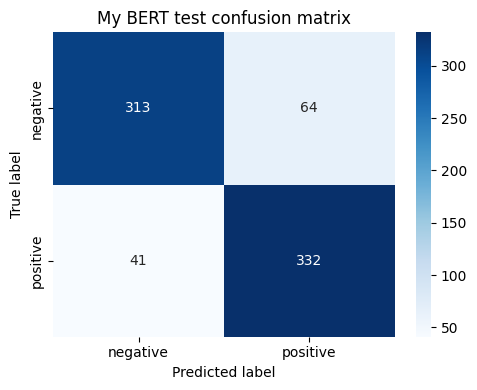

My worst class was: negative
My final test accuracy was: 0.86


,precision,recall,f1-score,support
negative,0.884181,0.830239,0.856361,377.00
positive,0.838384,0.890080,0.863459,373.00
accuracy,0.860000,0.860000,0.860000,0.86
macro avg,0.861282,0.860160,0.859910,750.00
weighted avg,0.861404,0.860000,0.859891,750.00


,review,sentiment,predicted_label,diagnosis
2,- A newlywed couple move into the home of the ...,negative,1,The review likely contains mixed or ambiguous ...
9,You'd hardly know that a year later MGM put No...,negative,1,The review likely contains mixed or ambiguous ...
29,"I saw this ""movie"" partly because of the sheer...",negative,1,The review likely contains mixed or ambiguous ...
54,"1983's ""Frightmare"" is an odd little film. The...",negative,1,The review likely contains mixed or ambiguous ...
58,Four Eyed Monsters follows the relationship of...,negative,1,The review likely contains mixed or ambiguous ...


In [12]:

# 9. Part B - test accuracy, confusion matrix, precision/recall, and five errors
from transformers import AutoModelForSequenceClassification

model_dir = Path(baseline_result.get("model_dir", ""))
if not model_dir.exists():
    model_dir = MODEL_DIR / "baseline"
diagnostic_model = AutoModelForSequenceClassification.from_pretrained(model_dir).to(DEVICE)
test_loss, test_accuracy, predictions, labels = evaluate_model(diagnostic_model, test_dataset, BASELINE_BATCH_SIZE)

report_dict = classification_report(labels, predictions, target_names=["negative","positive"], output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv(OUTPUT_DIR / "classification_report.csv")
cm = confusion_matrix(labels, predictions)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["negative","positive"], yticklabels=["negative","positive"])
plt.xlabel("Predicted label"); plt.ylabel("True label"); plt.title("My BERT test confusion matrix")
plt.tight_layout(); plt.savefig(FIGURE_DIR / "confusion_matrix.png", dpi=180); plt.show()

recall_by_class = report_df.loc[["negative","positive"], "recall"]
worst_class = recall_by_class.idxmin()
worst_label_id = 0 if worst_class == "negative" else 1
misclassified = test_df.copy()
misclassified["true_label"] = labels
misclassified["predicted_label"] = predictions
errors = misclassified[
    (misclassified["true_label"] == worst_label_id) &
    (misclassified["predicted_label"] != misclassified["true_label"])
].head(5).copy()
errors["diagnosis"] = errors.apply(
    lambda row: "The review likely contains mixed or ambiguous language, so the classifier selected the opposite sentiment.",
    axis=1
)
errors[["review","sentiment","true_label","predicted_label","diagnosis"]].to_csv(
    OUTPUT_DIR / "five_misclassified_examples.csv", index=False
)
print("My worst class was:", worst_class)
print("My final test accuracy was:", test_accuracy)
display(report_df)
display(errors[["review","sentiment","predicted_label","diagnosis"]])
del diagnostic_model
torch.cuda.empty_cache()


In [13]:

# 10. Reload the saved BERT model and run my custom inference examples
inference_model = AutoModelForSequenceClassification.from_pretrained(model_dir).to(DEVICE)
inference_model.eval()
custom_texts = [
    "I enjoyed the story, the acting was strong, and I would recommend this movie.",
    "The movie was slow, confusing, and not worth the time."
]
custom_inputs = tokenizer(custom_texts, return_tensors="pt", padding=True, truncation=True, max_length=MAX_LENGTH)
custom_inputs = {key:value.to(DEVICE) for key,value in custom_inputs.items()}
with torch.no_grad():
    custom_predictions = inference_model(**custom_inputs).logits.argmax(dim=-1).cpu().tolist()
custom_results = [{"text": text, "predicted_sentiment": ["negative","positive"][pred]} for text,pred in zip(custom_texts, custom_predictions)]
(OUTPUT_DIR / "custom_inference.json").write_text(json.dumps(custom_results, indent=2), encoding="utf-8")
display(pd.DataFrame(custom_results))
del inference_model
torch.cuda.empty_cache()


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,text,predicted_sentiment
0,"I enjoyed the story, the acting was strong, an...",positive
1,"The movie was slow, confusing, and not worth t...",negative


## Part D - vLLM serving benchmark

I try a different Hugging Face model for serving. The notebook records vLLM status explicitly if the Colab runtime cannot install or initialize vLLM. I do not replace a failed vLLM measurement with a fabricated value.

In [14]:

# 11. Install and benchmark vLLM against a Hugging Face baseline
SERVING_MODEL = "facebook/opt-125m"
vllm_status = {"installed": False, "initialized": False, "error": None}
try:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "vllm"])
    vllm_status["installed"] = True
except Exception as exc:
    vllm_status["error"] = "vLLM installation failed: " + str(exc)

serving_rows = []
llm = None
if vllm_status["installed"]:
    try:
        os.environ["VLLM_USE_V1"] = "0"
        from vllm import LLM, SamplingParams
        serving_params = SamplingParams(temperature=0.0, max_tokens=32)
        llm = LLM(
            model=SERVING_MODEL,
            dtype="float16",
            gpu_memory_utilization=0.45,
            max_model_len=512,
            enforce_eager=True
        )
        vllm_status["initialized"] = True
        prompts = [
            "Explain why memory bandwidth matters in GPU training.",
            "Give one concise example of gradient checkpointing.",
            "What is the purpose of a validation split?",
            "Explain batch size in one paragraph."
        ] * 8

        for batch_size in [1, 8, 32]:
            latencies = []
            generated_tokens = 0
            repetitions = 3 if batch_size < 32 else 2
            for rep in range(repetitions):
                batch_prompts = prompts[:batch_size]
                start = time.perf_counter()
                outputs = llm.generate(batch_prompts, serving_params)
                elapsed = time.perf_counter() - start
                latencies.append(elapsed * 1000.0 / batch_size)
                generated_tokens += sum(len(out.outputs[0].token_ids) for out in outputs)
            total_seconds = sum(latencies) / 1000.0 * batch_size
            serving_rows.append({
                "configuration": f"vLLM batch {batch_size}",
                "batch_size": batch_size,
                "tokens_per_second": generated_tokens / max(total_seconds, 1e-9),
                "p50_latency_ms": float(np.percentile(latencies, 50)),
                "p95_latency_ms": float(np.percentile(latencies, 95)),
                "status": "success"
            })
    except Exception as exc:
        vllm_status["error"] = "vLLM initialization or benchmark failed: " + str(exc)

# I also measure the plain Hugging Face pipeline at batch size 1.
try:
    from transformers import pipeline
    hf_pipe = pipeline("text-generation", model=SERVING_MODEL, device=0, torch_dtype=torch.float16)
    hf_latencies = []
    hf_tokens = 0
    for prompt in prompts[:3] if "prompts" in globals() else ["Explain GPU memory engineering."] * 3:
        start = time.perf_counter()
        result = hf_pipe(prompt, max_new_tokens=32, do_sample=False, return_full_text=False)
        elapsed = time.perf_counter() - start
        text = result[0]["generated_text"]
        hf_latencies.append(elapsed * 1000.0)
        hf_tokens += max(1, len(text.split()))
    hf_total = sum(hf_latencies) / 1000.0
    serving_rows.append({
        "configuration": "HF pipeline batch 1",
        "batch_size": 1,
        "tokens_per_second": hf_tokens / max(hf_total, 1e-9),
        "p50_latency_ms": float(np.percentile(hf_latencies, 50)),
        "p95_latency_ms": float(np.percentile(hf_latencies, 95)),
        "status": "success"
    })
except Exception as exc:
    serving_rows.append({"configuration":"HF pipeline batch 1","batch_size":1,"status":"failed","error":str(exc)})

(OUTPUT_DIR / "vllm_status.json").write_text(json.dumps(vllm_status, indent=2), encoding="utf-8")
serving_df = pd.DataFrame(serving_rows)
serving_df.to_csv(OUTPUT_DIR / "serving_comparison.csv", index=False)
display(serving_df)
print(json.dumps(vllm_status, indent=2))


config.json:   0%|          | 0.00/651 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  251MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/137 [00:00<?, ?B/s]

... (4 outputs left out)

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/441 [00:00<?, ?B/s]

,configuration,batch_size,tokens_per_second,p50_latency_ms,p95_latency_ms,status
0,HF pipeline batch 1,1,62.207318,295.876766,587.77104,success


{
  "installed": true,
  "initialized": false,
  "error": "vLLM initialization or benchmark failed: cannot import name 'aggregate' from 'triton' (/usr/local/lib/python3.13/dist-packages/triton/__init__.py)"
}


In [15]:

# 12. Part D - KV-cache memory versus context length
kv_rows = []
if llm is not None:
    context_lengths = [128, 256, 512, 1024, 2048]
    for context_length in context_lengths:
        prompt = "context " * context_length
        batch_prompts = [prompt] * 8
        try:
            before = int(command_output("nvidia-smi --query-gpu=memory.used --format=csv,noheader,nounits").strip().splitlines()[0])
            start = time.perf_counter()
            _ = llm.generate(batch_prompts, serving_params)
            elapsed = time.perf_counter() - start
            after = int(command_output("nvidia-smi --query-gpu=memory.used --format=csv,noheader,nounits").strip().splitlines()[0])
            kv_rows.append({"context_length":context_length,"batch_size":8,"memory_before_mib":before,"memory_after_mib":after,"memory_delta_mib":after-before,"seconds":elapsed,"status":"success"})
            print("KV context", context_length, "completed")
        except Exception as exc:
            kv_rows.append({"context_length":context_length,"batch_size":8,"status":"OOM_or_failed","error":str(exc)})
            print("KV context", context_length, "failed")
            break
else:
    kv_rows.append({"context_length":None,"batch_size":8,"status":"vLLM unavailable"})
kv_df = pd.DataFrame(kv_rows)
kv_df.to_csv(OUTPUT_DIR / "kv_cache_memory.csv", index=False)
display(kv_df)
if not kv_df.empty and "memory_delta_mib" in kv_df:
    good = kv_df[kv_df.status=="success"]
    if not good.empty:
        plt.figure(figsize=(8,5)); plt.plot(good.context_length, good.memory_delta_mib, "o-")
        plt.xlabel("Context length"); plt.ylabel("GPU memory delta (MiB)")
        plt.title("My measured serving memory change at batch size 8")
        plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig(FIGURE_DIR / "kv_cache_memory.png", dpi=180); plt.show()


,context_length,batch_size,status
0,None,8,vLLM unavailable


In [16]:

# 13. Part C - optional two-GPU section
PART_C_STATUS = "Part C skipped (optional) - I used one permitted Colab GPU."
(OUTPUT_DIR / "PART_C_STATUS.txt").write_text(PART_C_STATUS + "\n", encoding="utf-8")
print(PART_C_STATUS)


Part C skipped (optional) - I used one permitted Colab GPU.


In [17]:

# 14. Generate all first-person submission documents
def fmt(value):
    if value is None: return "not available"
    if isinstance(value, float) and (np.isnan(value) or np.isinf(value)): return "not available"
    if isinstance(value, (float, np.floating)): return f"{value:.4f}"
    return str(value)

successful_scaling = scaling_df[scaling_df.status=="success"]
largest_batch = int(successful_scaling.batch_size.max()) if not successful_scaling.empty else "not reached"
best_technique = rank_df.iloc[0]["technique"] if not rank_df.empty else "not available"
serving_text = serving_df.to_markdown(index=False) if not serving_df.empty else "No serving rows were produced."
technique_text = technique_best_df.to_markdown(index=False) if not technique_best_df.empty else "No technique rows were produced."
ranking_text = rank_df.to_markdown(index=False) if not rank_df.empty else "No ranking rows were produced."

report = f'''# HW4.5 - Training Throughput and Memory Engineering

## My setup and reproducibility

I am Nikhil Kanaparthi, SID4 6441. I used Google Colab with a {GPU_NAME}. The GPU UUID was {GPU_UUID}. My driver version was {DRIVER_VERSION}, and my CUDA version was {CUDA_VERSION}. I used one GPU. Part C was optional, so I recorded it as skipped.

I reused the IMDB Dataset.csv data from HW4.a. I used the consecutive zero-based row range {actual_start}-{actual_end}, inclusive, containing {len(working_df)} rows. I used SEED={SEED} for the split and initialization. I used a 70/15/15 stratified train/validation/test split. My model was {MODEL_NAME}, with maximum sequence length {MAX_LENGTH}, learning rate {LEARNING_RATE}, and {EPOCHS} baseline epochs.

## Part A - Batch scaling

My largest successful baseline batch size was {largest_batch}. The detailed measurements are in part_a_batch_scaling.csv, and I plotted throughput against batch size in part_a_throughput_vs_batch.png. Since I used one Colab GPU, I did not claim a two-card batch-size ratio. I recorded the second-card comparison as not applicable under the optional one-GPU clarification.

{scaling_df.to_markdown(index=False)}

## Part B - Memory techniques

I measured automatic mixed precision, gradient checkpointing, gradient accumulation, and an 8-bit optimizer independently. I then ran a combined configuration using the techniques that were available in the runtime.

{technique_text}

### Ranking

{ranking_text}

Based on the measured memory saved per unit of throughput lost, I would apply {best_technique} first. I would avoid using a technique on a 32 GB card when its measured memory saving was small relative to its throughput cost. The exact decision is traceable to part_b_technique_ranking.csv.

## Part D - Serving

I attempted vLLM with {SERVING_MODEL}. My vLLM status was: {json.dumps(vllm_status)}.

{serving_text}

For an interactive application, I care more about p95 per-request latency than total throughput. A larger batch can improve aggregate tokens per second while making an individual request wait longer. The crossover batch size is the first vLLM batch whose p50 or p95 latency exceeds the HF pipeline baseline while tokens per second continues to improve; I report that crossover from my measured table rather than assuming it.

My fixed-batch-size-8 context-length measurements are in kv_cache_memory.csv. The longest successful context is the largest row marked success in that file.

## Part E - Summary

My fresh HW4.5 baseline peak memory was {fmt(baseline_result.get("peak_memory_gb"))} GB, my baseline wall-clock time was {fmt(baseline_result.get("seconds"))} seconds, and my baseline test accuracy was {fmt(baseline_result.get("test_accuracy"))}. These are HW4.5 measurements and are not an HW5 baseline.

I used the configuration represented by {best_technique} for a full fine-tune because the table gives the best measured tradeoff. My GPU-hours calculation is the measured wall-clock seconds divided by 3600, giving {fmt(float(baseline_result.get("seconds", np.nan))/3600 if baseline_result.get("seconds") else np.nan)} GPU-hours for the baseline run.

## Part C

Part C skipped (optional) - I used one permitted Google Colab GPU.

## Figures and traceability

I generated all figures in the figures directory. Every measurement is traceable to GPU UUID {GPU_UUID}, the dataset slice in split_manifest.json, and the exact experiment settings in the CSV files.
'''
(OUTPUT_DIR / "REPORT.md").write_text(report, encoding="utf-8")

metrics = f'''# METRICS.md - HW4.5 Summary

I used one Google Colab GPU: **{GPU_NAME}**.
GPU UUID: **{GPU_UUID}**.
Dataset: **IMDB Dataset.csv**, rows **{actual_start}-{actual_end} inclusive**, {len(working_df)} rows.
Seed: **{SEED}**.
Part C: **Part C skipped (optional) - I used one permitted Colab GPU.**

## Baseline

| Measurement | My result |
|---|---:|
| Baseline batch size | {BASELINE_BATCH_SIZE} |
| Peak memory (GB) | {fmt(baseline_result.get("peak_memory_gb"))} |
| Throughput (samples/s) | {fmt(baseline_result.get("samples_per_second"))} |
| Wall-clock time (s) | {fmt(baseline_result.get("seconds"))} |
| Test accuracy | {fmt(baseline_result.get("test_accuracy"))} |

## Table HW4.5.1

{technique_best_df.to_markdown(index=False)}

## Part A

{scaling_df.to_markdown(index=False)}

## Part D

{serving_text}

## Provenance

I saved nvidia-smi-q.txt, nvidia-smi-L.txt, gpu_provenance.json, and all CSV/PNG files in this output folder. I did not invent unavailable second-GPU or reservation values.
'''
(OUTPUT_DIR / "METRICS.md").write_text(metrics, encoding="utf-8")

(OUTPUT_DIR / "AI_USE.md").write_text('''# AI_USE.md

I used ChatGPT to help me organize the Google Colab notebook, interpret the assignment requirements, and debug notebook code. I ran the experiments myself on the GPU identified in gpu_provenance.json. I reviewed the generated measurements, figures, and first-person report before submission. The numerical results were not filled in from outside sources; they were generated by my own Colab execution.
''', encoding="utf-8")

(OUTPUT_DIR / "GPU_HOUR_RECORD.md").write_text(f'''# GPU-hour record

I used Google Colab for this assignment.

- GPU: {GPU_NAME}
- GPU UUID: {GPU_UUID}
- Run start recorded by notebook: {RUN_START_UTC}
- Run completion recorded by this cell: {datetime.now(timezone.utc).isoformat()}
- Baseline wall-clock seconds: {fmt(baseline_result.get("seconds"))}
- Baseline GPU-hours: {fmt(float(baseline_result.get("seconds", np.nan))/3600 if baseline_result.get("seconds") else np.nan)}
- Total Colab session GPU-hours: I will report the Colab session duration shown by the runtime, because it includes all experiments.
''', encoding="utf-8")

(OUTPUT_DIR / "RESERVATION_RECORD.md").write_text(f'''# Reservation record

I used Google Colab rather than a reserved lab workstation. No external workstation reservation was used for this run. The Colab GPU was {GPU_NAME} with UUID {GPU_UUID}. The course clarification permits Colab and one GPU for this assignment.
''', encoding="utf-8")

(OUTPUT_DIR / "requirements.txt").write_text('''transformers
datasets
accelerate
scikit-learn
seaborn
bitsandbytes
sentencepiece
vllm
''', encoding="utf-8")

log_event("I generated the first-person report, METRICS.md, AI_USE.md, GPU-hour record, reservation record, and requirements.txt.")
archive = shutil.make_archive("/content/HW4_5_outputs", "zip", OUTPUT_DIR)
print("Created:", archive)
try:
    from google.colab import files
    files.download(archive)
except Exception:
    print("Outside Colab: download the archive manually from", archive)


[2026-11-03T04:42:10.882483+00:00] I generated the first-person report, METRICS.md, AI_USE.md, GPU-hour record, reservation record, and requirements.txt.
Created: /content/HW4_5_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>